In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

# import seaborn as sns
import os
from pathlib import Path




In [ ]:
DATA_PATH = "./data/"

TRAIN_PATH = DATA_PATH + "train.csv"
TEST_PATH = DATA_PATH + "test.csv"
SAMPLE_PATH = DATA_PATH + "sample_submission.csv"


df = pd.read_csv(
    './data/train.csv',
    usecols=["date", "store_nbr", "item_nbr", "unit_sales", "onpromotion"],
    dtype={
        # "id": "int32",
        "store_nbr": "int8",
        "item_nbr": "int32",
        "unit_sales": "float32",
        "onpromotion": "boolean",
    },
    parse_dates=["date"],
)

# Read only the first 100,000 rows for initial inspection
# df = pd.read_csv(
#     TRAIN_PATH,
#     nrows=100000,
#     parse_dates=["date"]
# )

# print(df.head())
# print(df.info())
# print(df.isnull().sum())

   id       date  store_nbr  item_nbr  unit_sales  onpromotion
0   0 2013-01-01         25    103665         7.0          NaN
1   1 2013-01-01         25    105574         1.0          NaN
2   2 2013-01-01         25    105575         2.0          NaN
3   3 2013-01-01         25    108079         1.0          NaN
4   4 2013-01-01         25    108701         1.0          NaN
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   id           100000 non-null  int64         
 1   date         100000 non-null  datetime64[us]
 2   store_nbr    100000 non-null  int64         
 3   item_nbr     100000 non-null  int64         
 4   unit_sales   100000 non-null  float64       
 5   onpromotion  0 non-null       float64       
dtypes: datetime64[us](1), float64(2), int64(3)
memory usage: 4.6 MB
None
id                  0
date                0
store_

In [4]:
latest_100 = df.sort_values(
    by='date',
    ascending=False
).head(100)

latest_100

,date,store_nbr,item_nbr,unit_sales,onpromotion
125497039,2017-08-15,54,2116416,2.0,False
125428501,2017-08-15,19,876223,1.0,False
125428491,2017-08-15,19,870545,2.0,False
125428492,2017-08-15,19,870546,4.0,False
125428493,2017-08-15,19,871600,1.0,False
...,...,...,...,...,...
125428534,2017-08-15,19,938574,9.0,False
125428535,2017-08-15,19,939129,3.0,False
125428536,2017-08-15,19,939130,6.0,False
125428537,2017-08-15,19,939131,4.0,False


In [5]:
print("Starting Date:", df['date'].min())
print("Latest Date:", df['date'].max())

Starting Date: 2013-01-01 00:00:00
Latest Date: 2017-08-15 00:00:00


In [6]:
# for col in df.select_dtypes(include=['number']):
#     thresh = df[col].quantile(0.95)
#     df[col] = df[col].clip(upper=thresh)

df.isnull().sum()

date                  0
store_nbr             0
item_nbr              0
unit_sales            0
onpromotion    21657651
dtype: int64

In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
# Check negative sales
print("Negative sales:", (df['unit_sales'] < 0).sum())

print("Zero sales:", (df['unit_sales'] == 0).sum())

Negative sales: 7795
Zero sales: 0


In [9]:
# Get 100 records belonging to the latest date
latest_date = df['date'].max()

latest_date_data = df[df['date'] == latest_date]

print(latest_date_data.head(100))

                date  store_nbr  item_nbr  unit_sales  onpromotion
125394228 2017-08-15          1    103665         1.0        False
125394229 2017-08-15          1    105574         4.0        False
125394230 2017-08-15          1    105575         8.0        False
125394231 2017-08-15          1    105577         2.0        False
125394232 2017-08-15          1    105693         1.0        False
...              ...        ...       ...         ...          ...
125394323 2017-08-15          1    215352         9.0        False
125394324 2017-08-15          1    215356         1.0        False
125394325 2017-08-15          1    215370         2.0        False
125394326 2017-08-15          1    215896         7.0        False
125394327 2017-08-15          1    217827         1.0        False

[100 rows x 5 columns]


In [10]:
print(latest_date_data.shape)

(102812, 5)


In [11]:
daily_sales = df.groupby('date')['unit_sales'].sum()

print(daily_sales.head())

date
2013-01-01      2511.619141
2013-01-02    496092.406250
2013-01-03    361429.218750
2013-01-04    354459.656250
2013-01-05    477350.125000
Name: unit_sales, dtype: float32


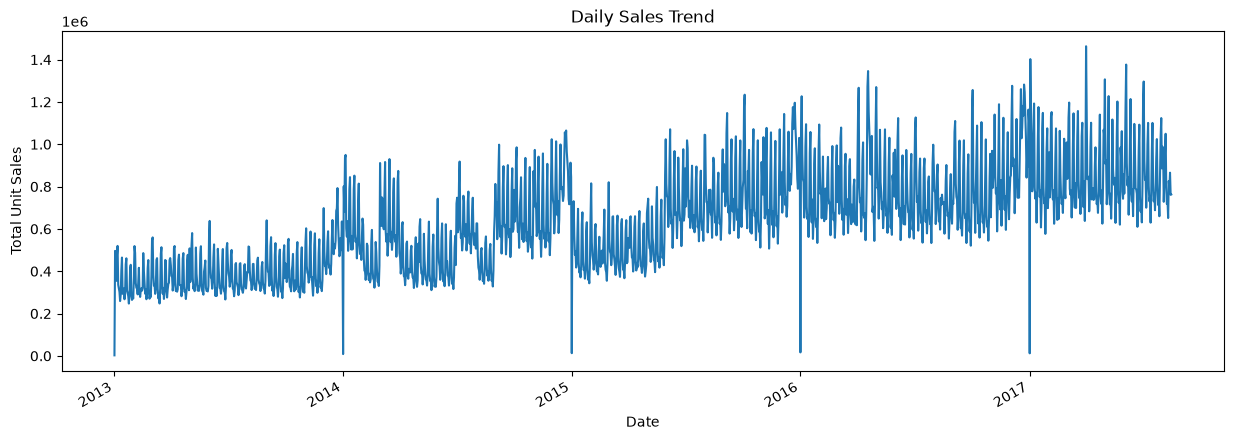

In [ ]:
# Visualize daily sales:
plt.figure(figsize=(15, 5))

daily_sales.plot()

plt.title('Daily Sales Trend')
plt.xlabel('Date')
plt.ylabel('Total Unit Sales')

plt.show()

In [13]:
# Sales by store
store_sales = (
    df.groupby('store_nbr')['unit_sales']
    .sum()
    .sort_values(ascending=False)
)

print(store_sales.head(10))

store_nbr
44    62087544.0
45    54498012.0
47    50948308.0
3     50481900.0
49    43420088.0
46    41896052.0
48    35933132.0
51    32911484.0
8     30491336.0
50    28653018.0
Name: unit_sales, dtype: float32


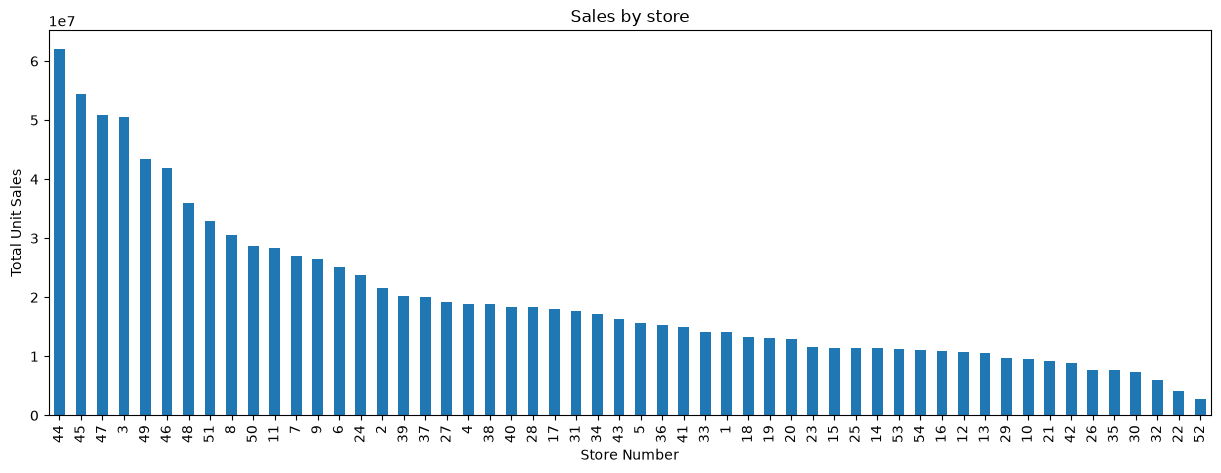

In [16]:
# Visualize Sales by store:
plt.figure(figsize=(15, 5))

store_sales.plot(kind='bar')

plt.title('Sales by store')
plt.xlabel('Store Number')
plt.ylabel('Total Unit Sales')

plt.show()

In [17]:
item_sales = (
    df.groupby('item_nbr')['unit_sales']
    .sum()
    .sort_values(ascending=False)
)

print(item_sales.head(10))

item_nbr
1503844    6264200.0
1047679    5512875.0
1473474    4990322.5
364606     4416426.0
819932     4410943.0
1463992    4408545.0
807493     4321424.0
265559     4112827.0
502331     3703350.0
314384     3544341.0
Name: unit_sales, dtype: float32


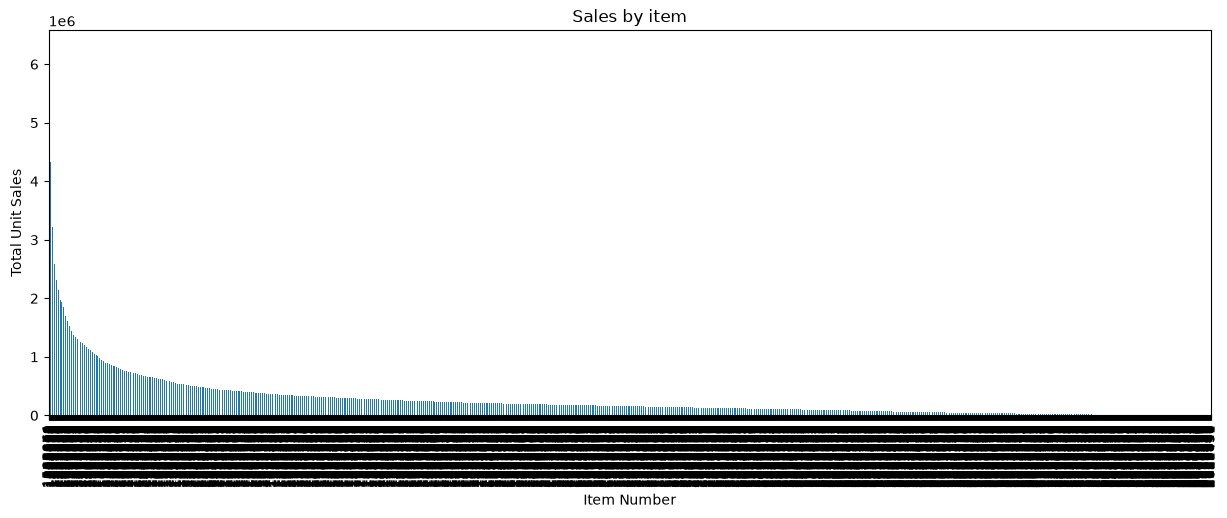

In [18]:
# Visualize Sales by item:
plt.figure(figsize=(15, 5))

item_sales.plot(kind='bar')

plt.title('Sales by item')
plt.xlabel('Item Number')
plt.ylabel('Total Unit Sales')

plt.show()

In [37]:
def update_date_features(df_input):
    df_input['year'] = df_input['date'].dt.year
    df_input['month'] = df_input['date'].dt.month
    df_input['day'] = df_input['date'].dt.day
    df_input['day_of_week'] = df_input['date'].dt.dayofweek
    df_input['week_of_year'] = df_input['date'].dt.isocalendar().week.astype('int8')
    return df_input.drop(columns=['date'])

In [ ]:
print("Before updating date features:", df.columns)
df = update_date_features(df)
print("After updating date features:", df.columns)

df.to_parquet('data_train.parquet')

In [44]:
df = pd.read_parquet('data_train.parquet')

In [20]:
df['is_weekend'] = (
    df['day_of_week'] >= 5
).astype('int8')

In [21]:
y = df['unit_sales']

In [22]:
features = [
    'store_nbr',
    'item_nbr',
    'onpromotion',
    'year',
    'month',
    'day',
    'day_of_week',
    'week_of_year',
    'is_weekend'
]

X = df[features]

In [54]:
df_test = pd.read_csv(
    TEST_PATH,
    parse_dates=["date"]
)
print("Before updating date features:", df_test.columns)
df_test = update_date_features(df_test)
print("After updating date features:", df_test.columns)

df_test.to_parquet('data_test.parquet')

sample_submission = pd.read_csv(SAMPLE_PATH)

print("Test shape:", df_test.shape)
print("Sample submission shape:", sample_submission.shape)

display(df_test.head())
display(sample_submission.head())

Before updating date features: Index(['id', 'date', 'store_nbr', 'item_nbr', 'onpromotion'], dtype='str')


/var/folders/w4/1jsq333x2nxcldzy6b620_fw0000gn/T/ipykernel_10420/3904350479.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_input['day_of_week'] = df_input['date'].dt.dayofweek


After updating date features: Index(['id', 'store_nbr', 'item_nbr', 'onpromotion', 'year', 'month', 'day',
       'day_of_week', 'week_of_year'],
      dtype='str')
Test shape: (3370464, 9)
Sample submission shape: (3370464, 2)


,id,store_nbr,item_nbr,onpromotion,year,month,day,day_of_week,week_of_year
0,125497040,1,96995,False,2017,8,16,2,33
1,125497041,1,99197,False,2017,8,16,2,33
2,125497042,1,103501,False,2017,8,16,2,33
3,125497043,1,103520,False,2017,8,16,2,33
4,125497044,1,103665,False,2017,8,16,2,33


,id,unit_sales
0,125497040,1.875000
1,125497041,1.900000
2,125497042,4.053548
3,125497043,1.904762
4,125497044,3.217391


In [ ]:
df_test = pd.read_parquet('data_test.parquet')

In [27]:
def build_sales_statistics(start_date, end_date):

    pair_parts = []
    item_parts = []

    for chunk in pd.read_csv(
        TRAIN_PATH,
        usecols=["date", "store_nbr", "item_nbr", "unit_sales"],
        parse_dates=["date"],
        chunksize=2_000_000
    ):

        chunk = chunk[
            (chunk["date"] >= start_date) &
            (chunk["date"] <= end_date)
        ].copy()

        if chunk.empty:
            continue

        chunk["unit_sales"] = chunk["unit_sales"].clip(lower=0)

        pair_stats = chunk.groupby(
            ["store_nbr", "item_nbr"]
        )["unit_sales"].agg(["sum", "count"])

        item_stats = chunk.groupby(
            "item_nbr"
        )["unit_sales"].agg(["sum", "count"])

        pair_parts.append(pair_stats)
        item_parts.append(item_stats)

    # Combine statistics from all chunks
    pair_all = pd.concat(pair_parts).groupby(
        level=[0, 1]
    ).sum()

    item_all = pd.concat(item_parts).groupby(
        level=0
    ).sum()

    pair_all["pair_avg"] = pair_all["sum"] / pair_all["count"]
    item_all["item_avg"] = item_all["sum"] / item_all["count"]

    global_avg = pair_all["sum"].sum() / pair_all["count"].sum()

    return (
        pair_all[["pair_avg"]],
        item_all[["item_avg"]],
        global_avg
    )

In [29]:
def predict_sales(data, pair_stats, item_stats, global_avg):

    result = data.merge(
        pair_stats,
        left_on=["store_nbr", "item_nbr"],
        right_index=True,
        how="left"
    )

    result = result.merge(
        item_stats,
        left_on="item_nbr",
        right_index=True,
        how="left"
    )

    result["unit_sales"] = result["pair_avg"]

    result["unit_sales"] = result["unit_sales"].fillna(
        result["item_avg"]
    )

    result["unit_sales"] = result["unit_sales"].fillna(
        global_avg
    )

    result["unit_sales"] = result["unit_sales"].clip(lower=0)

    return result["unit_sales"].to_numpy()

In [28]:
pair_stats, item_stats, global_avg = build_sales_statistics(
    "2017-07-17",
    "2017-08-15"
)

print("Sales statistics are ready!")


Sales statistics are ready!


In [41]:
predictions = predict_sales(
    df_test,
    pair_stats,
    item_stats,
    global_avg
)

print("Predictions generated:", len(predictions))
print(predictions[:10])

Predictions generated: 3370464
[ 1.875       1.9         4.05354752  1.9047619   3.2173913   5.67857143
 10.63333333 18.97128589  1.73333333  1.2       ]


In [33]:
submission = sample_submission[["id"]].copy()

submission["unit_sales"] = predictions

display(submission.head(1000))

,id,unit_sales
0,125497040,1.875000
1,125497041,1.900000
2,125497042,4.053548
3,125497043,1.904762
4,125497044,3.217391
...,...,...
995,125498035,1.333333
996,125498036,1.600000
997,125498037,1.888889
998,125498038,1.973607


In [35]:
submission.to_csv("./data/sample_submission.csv", index=False)

print("sample_submission.csv updated successfully!")

sample_submission.csv updated successfully!


In [49]:
X_train = df.drop(columns=["unit_sales"])
y_train = df.loc[:, "unit_sales"]

In [57]:
print("Training columns:")
print(X_train.columns.tolist())

print("\nTest columns:")
print(df_test.columns.tolist())

Training columns:
['id', 'store_nbr', 'item_nbr', 'onpromotion', 'year', 'month', 'day', 'day_of_week', 'week_of_year']

Test columns:
['id', 'store_nbr', 'item_nbr', 'onpromotion', 'year', 'month', 'day', 'day_of_week', 'week_of_year']


In [ ]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Preprocessing of training data, fit model
rf_model.fit(X_train, y_train)


X_test = df_test[X_train.columns]

pred = rf_model.predict(X_test)

# Create submission
submission = pd.DataFrame({
    'id': df_test['id'],
    'unit_sales': pred
})

submission.to_csv("prediction.csv", index=False)
print("prediction.csv generated successfully!", submission.head(10))

df_test.columns

prediction.csv generated successfully!           id  unit_sales
0  125497040    46.71411
1  125497041    46.71411
2  125497042    46.71411
3  125497043    46.71411
4  125497044    46.79411
5  125497045    46.95411
6  125497046    46.93411
7  125497047    46.93411
8  125497048    46.79135
9  125497049    46.74135


Index(['id', 'store_nbr', 'item_nbr', 'onpromotion', 'year', 'month', 'day',
       'day_of_week', 'week_of_year'],
      dtype='str')

NameError: name 'df' is not defined